# SYNCEDSTRUCTURE
### **A Class to handle, crossreference and annotate Structural Proteomics Data**

Credits:
LICENCES:

In [1]:
### <DEPENDENCIES and SyncedStructure Methods display> 
import re, urllib.request, requests, io, copy, os, pickle
import math, string
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch, Rectangle
import pandas as pd
import seaborn as sns
from synced_structure import SyncedStructure
from viz3d import side_by_side

def get_uniprot(uid):
    u = str(uid).strip().upper()
    if not re.match(r"^([OPQ][0-9][A-Z0-9]{3}[0-9]|[A-NR-Z][0-9]([A-Z][A-Z0-9]{2}[0-9]){1,2})(-\d+)?$", u):
        raise ValueError()
    buf = io.StringIO(urllib.request.urlopen(f"https://rest.uniprot.org/uniprotkb/{u}.fasta").read().decode())
    return u, "".join(buf.read().splitlines()[1:])


pd.set_option("display.width", 1000)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 100)

synced_structure_options = dir(SyncedStructure)
d = [x for x in synced_structure_options if x.startswith("__")]
h = [x for x in synced_structure_options
    if x.startswith("_") and not x.startswith("__")]
e = [x for x in synced_structure_options if not x.startswith("_")]
for g in (d, h, e):
  if g:
    [print(g[i : i + 4]) for i in range(0, len(g), 4)]
    print()
### <\DEPENDENCIES and SyncedStructure Methods display>


['__class__', '__contains__', '__delattr__', '__dict__']
['__dir__', '__doc__', '__eq__', '__firstlineno__']
['__format__', '__ge__', '__getattribute__', '__getitem__']
['__getstate__', '__gt__', '__hash__', '__init__']
['__init_subclass__', '__iter__', '__le__', '__len__']
['__lt__', '__module__', '__ne__', '__new__']
['__reduce__', '__reduce_ex__', '__repr__', '__setattr__']
['__sizeof__', '__static_attributes__', '__str__', '__subclasshook__']
['__weakref__']

['_angles_overlay', '_apply_chain_options', '_atom_contacts', '_atom_pair_maps']
['_auth_of', '_block_entries', '_build_chains', '_ca_records']
['_chain_colors', '_chain_contact_partners', '_chain_description_map', '_chain_entity_map']
['_chain_geometry', '_chain_name', '_checked_matrix', '_clean_val']
['_compute_interface', '_compute_local_alignment', '_coords_touch', '_draw_pair']
['_entity_sequences', '_external_refs_for_entity', '_gray_matrix', '_heavy_atoms']
['_hydrophobicity', '_keep_mapped', '_label_of', '_local_alignm

### ZIKV Monoclonal Antibodies

| Monoclonal Antibody | PDB ID | Reference & Description |
| ------------------- | ------ | ----------------------- |
| **ZIKV-195** | `6MID` | Cryo-EM structure of the ZIKV virion complexed with ZIKV-195 Fab fragments. Long et al. (2019), *PNAS*. [DOI](https://doi.org/10.1073/pnas.1815432116). |
| **EDE2 A11** | `5LCV` | Crystal structure of the Zika virus envelope protein in complex with the broadly neutralizing antibody EDE2 A11. Barba-Spaeth et al. (2016), *Nature*. [DOI](https://doi.org/10.1038/nature18938). |
| **EDE1 C8** | `5LBS` | Crystal structure of the Zika virus envelope protein in complex with EDE1 C8, a broadly neutralizing antibody recognizing a conserved epitope shared between Zika and dengue viruses. Barba-Spaeth et al. (2016), *Nature*. [DOI](https://doi.org/10.1038/nature18938). |
| **ZIKV-117** | `5KVE` | Structure of the Zika virus envelope protein in complex with ZIKV-117, a potent human monoclonal antibody targeting a quaternary epitope on the viral surface. [RCSB PDB](https://www.rcsb.org/structure/5KVE). |

In [13]:
### <RETRIEVAL, MAPPING and VISUALIZATION>
NICKNAME = "zikv"
PDB_IDS = ["6MID", "5LCV", "5LBS", "5KVE"]
pdb_angles = [(-50, 55, -150), (-21, -6, 86), (101, -48, -104), (74, -21, -110)]
upid_list = ["A0A142I5B9"]
PDBS_THERE = {
    "query": {
        "type": "terminal",
        "service": "text",
        "parameters": {
            "attribute": "rcsb_polymer_entity_container_identifiers.reference_sequence_identifiers.database_accession",
            "operator": "in",
            "value": upid_list
        }
    },
    "return_type": "entry",
    "request_options": {"paginate": {"start": 0, "rows": 250}}
}
payload = PDBS_THERE
print(payload)
upseq = get_uniprot(upid_list[0])
print(f"{upseq[0]}: {upseq[1][:50]}...")
synced_list = [SyncedStructure.from_rcsb_id(pid) for pid in PDB_IDS]
sync_summaries = []
for pdb_id, sync in zip(PDB_IDS, synced_list):
    summary = sync.summary()
    if isinstance(summary, dict):
        summary['pdb_id'] = pdb_id
        sync_summaries.append(summary)
    elif isinstance(summary, pd.DataFrame):
        summary = summary.copy()
        summary['pdb_id'] = pdb_id
        sync_summaries.append(summary)
sync_df = pd.concat(sync_summaries, ignore_index=True) if sync_summaries and isinstance(sync_summaries[0], pd.DataFrame) else pd.DataFrame(sync_summaries)
structure_neighbours = {}
matched_by_pdb = {}
for pdb_id, sync in zip(PDB_IDS, synced_list):
    try:
        mc = sync.match_chains(upseq[1])
        mc = mc[mc['query_coverage_percent'] > 1]
        matched_ids = mc['auth_chain_id'].tolist()
        partners_dict = sync._chain_contact_partners(cutoff=1.0)
        neighbour_set = set()
        for mid in matched_ids:
            neighbour_set.update(partners_dict.get(mid, []))
        neighbour_set -= set(matched_ids)
        structure_neighbours[pdb_id] = list(neighbour_set)
        matched_by_pdb[pdb_id] = matched_ids
    except Exception:
        matched_by_pdb[pdb_id] = []
        structure_neighbours[pdb_id] = []
upseq = get_uniprot(upid_list[0])
viz_list = []
crimson = "#b8483b"
pea = "#acdf74"
base = "#c7d0be"
for pdb_id, sync, angles in zip(PDB_IDS, synced_list, pdb_angles):
    if pdb_id not in matched_by_pdb:
        continue
    matched_ids = matched_by_pdb[pdb_id]
    partners = structure_neighbours.get(pdb_id, [])
    for focus in matched_ids:
        sync.set_reference_sequence(chain_id=focus, sequence=upseq[1], remap=True)
        sync.set_external_ref(chain_id=focus, external_ref=upseq[0])
        sync.remap_chain(focus)
    title = f"Envelope ({pdb_id})"
    all_chains = sync.chain_ids
    palette = {c: base for c in all_chains}
    for c in partners:
        palette[c] = pea
    for c in matched_ids:
        palette[c] = crimson
    plot = sync.jupy_viz(title=title, colors=palette, size=200, style='sphere', angles=angles)
    viz_list.append(plot)
side_by_side(*viz_list)
### <\RETRIEVAL, MAPPING and VISUALIZATION>

{'query': {'type': 'terminal', 'service': 'text', 'parameters': {'attribute': 'rcsb_polymer_entity_container_identifiers.reference_sequence_identifiers.database_accession', 'operator': 'in', 'value': ['A0A142I5B9']}}, 'return_type': 'entry', 'request_options': {'paginate': {'start': 0, 'rows': 250}}}
A0A142I5B9: MKNPKKKSGGFRIVNMLKRGVARVSPFGGLKRLPAGLLLGHGPIRMVLAI...
[PYTHON-INFO] 2026-10-17 19:18:52 | Loaded RCSB structure 6MID | execution time: 1.50s | max memory: 548.3 MB
[PYTHON-INFO] 2026-10-17 19:18:53 | Loaded RCSB structure 5LCV | execution time: 1.18s | max memory: 548.3 MB
[PYTHON-INFO] 2026-10-17 19:18:55 | Loaded RCSB structure 5LBS | execution time: 1.19s | max memory: 548.3 MB
[PYTHON-INFO] 2026-10-17 19:18:55 | Loaded RCSB structure 5KVE | execution time: 0.46s | max memory: 548.3 MB
remapped B
remapped D
remapped F
remapped A
remapped C
remapped E
[PYTHON-INFO] 2026-10-17 19:18:57 | Rendered view of 6MID at angles (-50, 55, -150) | execution time: 1.04s | max memory: 548.

In [3]:
### <NAMING STRUCTURES OF INTEREST>
pdb_6mid = synced_list[0]
if 'A' in pdb_6mid.chain_ids:
    pdb_6mid.remove_chain('A')
if 'B' in pdb_6mid.chain_ids:
    pdb_6mid.remove_chain('B')
if 'G' in pdb_6mid.chain_ids:
    pdb_6mid.remove_chain('G')
pdb_5lcv = synced_list[1]
### <\NAMING STRUCTURES OF INTEREST>

In [4]:
print(pdb_6mid.summary())

  chain_id auth_chain_id entity_id                                                                              description      external_ref  sequence_length  reference_length  mapped_residues  mapping_fraction
0        C             C         1                                                                                E protein        A0A142I5B9              501              3423              501               1.0
1        D             D         2                                                                                M protein        A0A142I5B9               75              3423               75               1.0
2        E             E         1                                                                                E protein        A0A142I5B9              501              3423              501               1.0
3        F             F         2                                                                                M protein        A0A142I5B9           

In [5]:

palette_6mid = {'H':'#037ace', 'L':'#6fbfff', 'E':'#e76f51', 'C':'#c14d30', 'B':'#ac69ca', 'D':'#ac69ca', 'F':'#ac69ca', 'I':'#d5b517', 'J':'#d5b517'}
palette_5lcv = {'H':'#037ace', 'L':'#6fbfff', 'A':'#e76f51', 'B':'#c14d30', 'C':'#d5b517'}
viz_list_detail = []
viz_list_detail.append(pdb_6mid.jupy_viz(style="sphere", colors=palette_6mid, size=350, title="6MID"))
viz_list_detail.append(pdb_5lcv.jupy_viz(style="sphere", colors=palette_5lcv, size=350, title="5LCV", angles=(20,-30,80)))
side_by_side(*viz_list_detail)

[PYTHON-INFO] 6MID: colors ignored for unloaded chains ['B']
[PYTHON-INFO] 2026-10-17 19:01:16 | Rendered view of 6MID at angles (0, 0, 0) | execution time: 0.74s | max memory: 349.1 MB
[PYTHON-INFO] 2026-10-17 19:01:17 | Rendered view of 5LCV at angles (20, -30, 80) | execution time: 0.67s | max memory: 356.8 MB


In [6]:
pdb_6mid.jupy_viz(style="sphere", colors=palette_6mid, size=350, title="6MID", angles=(0,90,90))

[PYTHON-INFO] 6MID: colors ignored for unloaded chains ['B']
[PYTHON-INFO] 2026-10-17 19:01:18 | Rendered view of 6MID at angles (0, 90, 90) | execution time: 1.02s | max memory: 358.9 MB


In [7]:
### <HELPERS_VIZ>
set1_palette = [
    "#e41a1c",
    "#377eb8",
    "#4daf4a",
    "#984ea3",
]

def plot_grid_with_letters(plot_funcs, sizes, ncols=2, panel_labels=True, main_title=None, wspace=0.2, hspace=0.2):
    n = len(plot_funcs)
    nrows = math.ceil(n / ncols)
    full_sizes = sizes + [sizes[-1]] * (nrows * ncols - n)
    size_grid = [full_sizes[i*ncols:(i+1)*ncols] for i in range(nrows)]
    row_heights = [max(row) for row in size_grid]
    col_widths = [max(size_grid[r][c] for r in range(nrows)) for c in range(ncols)]
    fig = plt.figure(figsize=(sum(col_widths), sum(row_heights)))
    gs = fig.add_gridspec(nrows, ncols, width_ratios=col_widths, height_ratios=row_heights, wspace=wspace, hspace=hspace)
    if main_title:
        fig.suptitle(main_title, fontsize=16, fontweight='bold', y=0.95)
    axes = []
    for i, f in enumerate(plot_funcs):
        r, c = divmod(i, ncols)
        ax = fig.add_subplot(gs[r, c])
        f(ax=ax)
        if panel_labels and i < len(string.ascii_uppercase):
            ax.text(-0.12, 1.05, string.ascii_uppercase[i], transform=ax.transAxes, fontsize=14, fontweight='bold', va='bottom', ha='right')
        axes.append(ax)
    plt.show()
    return fig, axes

### <\HELPERS-VIZ>

  chain_id auth_chain_id entity_id          description      external_ref  sequence_length  reference_length  mapped_residues  mapping_fraction
0        C             C         1            E protein        A0A142I5B9              501              3423              501               1.0
1        D             D         2            M protein        A0A142I5B9               75              3423               75               1.0
2        E             E         1            E protein        A0A142I5B9              501              3423              501               1.0
3        F             F         2            M protein        A0A142I5B9               75              3423               75               1.0
4        G             H         3  monoclonal antib...               NaN              127               128              127               1.0
5        H             L         4  monoclonal antib...  6MID, A0A0B4J1U3              110               110              110           

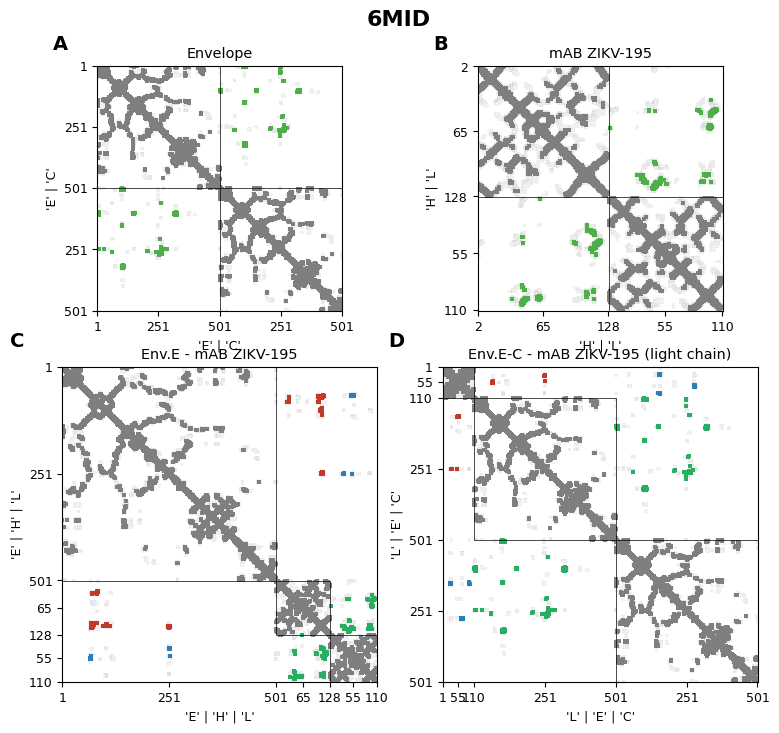

In [8]:
pd.set_option('display.max_colwidth', 20)
print(pdb_6mid.summary())
cts_mtx_list = [
    lambda ax: pdb_6mid.plot_contacts_two('E', 'C', cutoff=1, n_ticks=3, tick_size=9, font_size=9, ax=ax, inter_color=set1_palette[2], title="Envelope"),
    lambda ax: pdb_6mid.plot_contacts_two('H', 'L', cutoff=1, n_ticks=3, tick_size=9, font_size=9, ax=ax, inter_color=set1_palette[2], title="mAB ZIKV-195"),
    lambda ax: pdb_6mid.plot_contacts_three('E', 'H', 'L', cutoff=1, n_ticks=3, tick_size=9, font_size=9, ax=ax, title="Env.E - mAB ZIKV-195"),
    lambda ax: pdb_6mid.plot_contacts_three('L', 'E', 'C', cutoff=1, n_ticks=3, tick_size=9, font_size=9, ax=ax, title="Env.E-C - mAB ZIKV-195 (light chain)")
]
panel_sizes = [3.5, 3.5, 4.5, 4.5]
fig, axes = plot_grid_with_letters(cts_mtx_list, sizes=panel_sizes, main_title='6MID')

  chain_id auth_chain_id entity_id          description external_ref  sequence_length  reference_length  mapped_residues  mapping_fraction
0        A             A         1          Polyprotein   A0A142I5B9              406              3423              406               1.0
1        B             B         1          Polyprotein   A0A142I5B9              405              3423              405               1.0
2        C             H         2  BROADLY NEUTRALI...          NaN              226               283              226               1.0
3        D             L         3  BROADLY NEUTRALI...         5LCV              212               216              212               1.0
4        E             C         4  beta-D-mannopyra...          NaN                0                 0                0               0.0


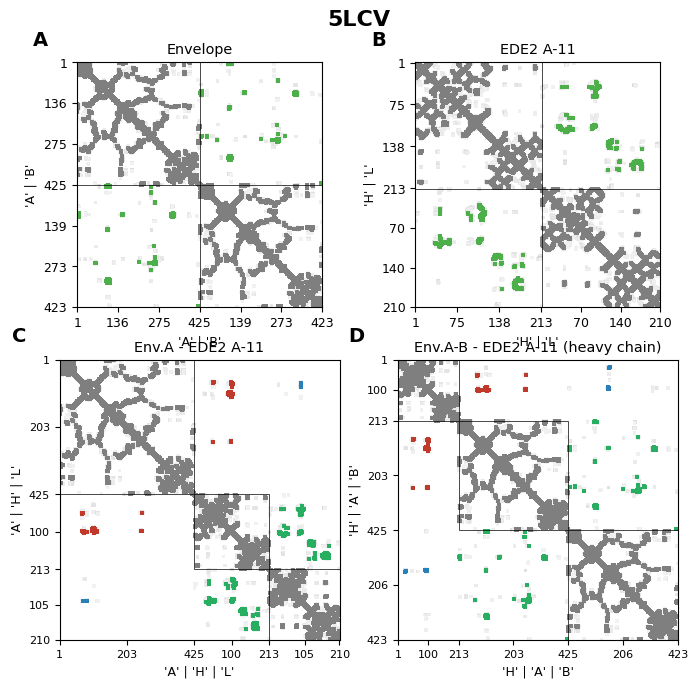

In [9]:
pd.set_option('display.max_colwidth', 20)
print(pdb_5lcv.summary())
cts_mtx_list = [
    lambda ax: pdb_5lcv.plot_contacts_two('A', 'B', cutoff=1, tick_size=9, font_size=9, ax=ax, inter_color=set1_palette[2], title="Envelope"),
    lambda ax: pdb_5lcv.plot_contacts_two('H', 'L', cutoff=1, tick_size=9, font_size=9, ax=ax, inter_color=set1_palette[2], title="EDE2 A-11"),
    lambda ax: pdb_5lcv.plot_contacts_three('A', 'H', 'L', cutoff=1, n_ticks=3, tick_size=8, font_size=9, ax=ax, title="Env.A - EDE2 A-11"),
    lambda ax: pdb_5lcv.plot_contacts_three('H', 'A', 'B', cutoff=1, n_ticks=3, tick_size=8, font_size=9, ax=ax, title="Env.A-B - EDE2 A-11 (heavy chain)")
]
panel_sizes = [3.5, 3.5, 4, 4]
fig, axes = plot_grid_with_letters(cts_mtx_list, sizes=panel_sizes, main_title='5LCV')